<a href="https://colab.research.google.com/github/emilige/Works/blob/main/Multicity_MFD_Ocupacion_Critica_ARI_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multicity — MFD, ocupación crítica y ARI
Código completo de estas etapas, extraído de los scripts comprobados v1.0. Ejecuta las celdas en orden. Se adaptan las rutas y se separan los bloques; se conservan los cálculos, filtros y semillas. No se ejecutan las etapas posteriores de alertas ni ponderación espacial.

## 1. Instalar dependencias
Se usan las versiones del paquete comprobado. Ejecuta esta celda antes de importar las bibliotecas.

In [ ]:
import sys, subprocess
subprocess.check_call([sys.executable, "-m", "pip", "install", 'duckdb==2.0.0', 'numpy==2.3.5', 'pandas==2.2.3', 'scikit-learn==1.8.0', 'matplotlib==3.10.8', 'pyarrow==26.0.0', 'scipy==1.17.0'])

0

## 2. Conectar Google Drive y localizar los datos
Coloca los Parquet originales por ciudad en la carpeta indicada, o cambia DATA. Se requieren los ocho archivos de la lista SELECTED. Para reproducir también el cribado de todo el archivo, coloca los 40 Parquet. El paquete no redistribuye UTD19 ni contiene la conversión original a Parquet. El código exige columnas day, interval, detid, error, flow, occ y speed; interval está en segundos desde medianoche y occ entre 0 y 1. Usa los insumos autorizados de https://utd19.ethz.ch/ y el inventario config/source_file_index.json del paquete para comprobarlos.

In [ ]:
import zipfile, pathlib, shutil

# Buscar donde quedó tu zip
for p in [pathlib.Path("/content/UTD19_PARQUET.zip"), pathlib.Path("/content/drive/MyDrive/UTD19_PARQUET.zip")]:
    print(p, p.exists())

# Descomprimir en la carpeta que pide el cuaderno
DATA = pathlib.Path("/content/drive/MyDrive/UTD19/CIUDADES_PARQUET")
DATA.mkdir(parents=True, exist_ok=True)

zip_path = pathlib.Path("/content/UTD19_PARQUET.zip")
if zip_path.exists():
    print("Descomprimiendo desde /content...")
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(DATA)
    print("Listo!")

print(list(DATA.iterdir())[:20])

/content/UTD19_PARQUET.zip True
/content/drive/MyDrive/UTD19_PARQUET.zip False
Descomprimiendo desde /content...
Listo!
[PosixPath('/content/drive/MyDrive/UTD19/CIUDADES_PARQUET/CIUDADES_PARQUET')]


In [ ]:
import pathlib, shutil

DATA = pathlib.Path("/content/drive/MyDrive/UTD19/CIUDADES_PARQUET")
# Buscar si quedaron en una subcarpeta
for sub in DATA.iterdir():
    if sub.is_dir():
        print("Subcarpeta encontrada:", sub)
        for f in sub.iterdir():
            print("Moviendo:", f.name)
            shutil.move(str(f), str(DATA / f.name))
        print("Listo, movidos!")

print("Ahora en DATA hay:")
print(list(DATA.iterdir())[:20])

Subcarpeta encontrada: /content/drive/MyDrive/UTD19/CIUDADES_PARQUET/CIUDADES_PARQUET
Moviendo: augsburg.parquet
Moviendo: basel.parquet
Moviendo: bern.parquet
Moviendo: birmingham.parquet
Moviendo: bolton.parquet
Moviendo: bordeaux.parquet
Moviendo: bremen.parquet
Moviendo: cagliari.parquet
Moviendo: constance.parquet
Moviendo: darmstadt.parquet
Moviendo: essen.parquet
Moviendo: frankfurt.parquet
Moviendo: graz.parquet
Moviendo: groningen.parquet
Moviendo: hamburg.parquet
Moviendo: innsbruck.parquet
Moviendo: kassel.parquet
Moviendo: london.parquet
Moviendo: losangeles.parquet
Moviendo: luzern.parquet
Moviendo: madrid.parquet
Moviendo: manchester.parquet
Moviendo: marseille.parquet
Moviendo: melbourne.parquet
Moviendo: munich.parquet
Moviendo: paris.parquet
Moviendo: rotterdam.parquet
Moviendo: santander.parquet
Moviendo: speyer.parquet
Moviendo: strasbourg.parquet
Moviendo: stuttgart.parquet
Moviendo: taipeh.parquet
Moviendo: tokyo.parquet
Moviendo: torino.parquet
Moviendo: toronto.p

In [ ]:
from google.colab import drive
from pathlib import Path
drive.mount("/content/drive", force_remount=True)
DATA = Path("/content/drive/MyDrive/UTD19/CIUDADES_PARQUET")
OUT = Path("/content/drive/MyDrive/UTD19/resultados_multicity")
OUT.mkdir(parents=True, exist_ok=True)
SELECTED=['cagliari','darmstadt','hamburg','luzern','marseille','paris','tokyo','toronto']
missing = [c for c in SELECTED if not (DATA / f"{c}.parquet").is_file()]
if missing:
    raise FileNotFoundError(f"Faltan Parquet en {DATA}: {missing}")


Mounted at /content/drive


## 3. Cribado y umbral de cobertura
Se ejecuta screen_cities.py sobre los Parquet presentes. El umbral es el techo del 50 % del percentil 95 de registros concurrentes sin error. El conjunto usado para calcular las medias exige además flujo y ocupación válidos.

In [ ]:
from pathlib import Path
import json, math
import duckdb
import pandas as pd
import numpy as np

if not list(DATA.glob("*.parquet")): raise SystemExit(f"No city Parquet files in {DATA}")


def qident(path: Path) -> str:
    return str(path).replace("'", "''")


records = []
con = duckdb.connect()
for p in sorted(DATA.glob("*.parquet")):
    src = qident(p)
    base = con.execute(f"""
        SELECT count(*) AS n_rows,
               count(DISTINCT detid) AS n_detectors,
               count(DISTINCT day) AS n_days,
               min(day) AS day_min, max(day) AS day_max,
               count(*) FILTER (WHERE occ IS NOT NULL) AS occ_present,
               count(*) FILTER (WHERE speed IS NOT NULL) AS speed_present,
               count(*) FILTER (WHERE error=1) AS invalid_flag,
               count(*) FILTER (WHERE (error IS NULL OR error=0)
                                  AND flow>0 AND occ>0 AND occ<=1
                                  AND isfinite(flow) AND isfinite(occ)) AS valid_active,
               min(interval) AS interval_min, max(interval) AS interval_max,
               count(DISTINCT interval) AS interval_values
        FROM read_parquet('{src}')
    """).fetchone()
    rows, ndet, ndays, dmin, dmax, occp, speedp, inv, active, imin, imax, niv = base
    cadence = con.execute(f"""
        WITH x AS (SELECT DISTINCT interval FROM read_parquet('{src}') WHERE interval<86400),
        y AS (SELECT interval-lag(interval) OVER(ORDER BY interval) d FROM x)
        SELECT mode(d) FILTER(WHERE d>0) FROM y
    """).fetchone()[0]
    concurrent = con.execute(f"""
        SELECT quantile_cont(reporting, 0.95), max(reporting)
        FROM (
          SELECT day, interval, count(*) FILTER(WHERE error IS NULL OR error=0) reporting
          FROM read_parquet('{src}') GROUP BY day, interval
        )
    """).fetchone()
    reference_concurrent = float(concurrent[0] or 0)
    max_concurrent = int(concurrent[1] or 0)
    threshold = math.ceil(0.50 * reference_concurrent)
    agg = con.execute(f"""
        WITH coverage AS (
          SELECT day, interval,
                 count(*) FILTER(WHERE error IS NULL OR error=0) reporting,
                 avg(flow) FILTER(WHERE (error IS NULL OR error=0) AND flow>0 AND occ>0 AND occ<=1
                                  AND isfinite(flow) AND isfinite(occ)) q,
                 avg(occ) FILTER(WHERE (error IS NULL OR error=0) AND flow>0 AND occ>0 AND occ<=1
                                 AND isfinite(flow) AND isfinite(occ)) o
          FROM read_parquet('{src}') GROUP BY day, interval
        )
        SELECT day, interval, reporting, q, o FROM coverage
        WHERE reporting >= {threshold} AND q IS NOT NULL AND o IS NOT NULL
    """).df()
    eligible = len(agg)
    beta0=beta1=beta2=r2=crit_occ=max_flow=np.nan
    concave=False; vertex_inside=False
    oq05=oq50=oq95=np.nan
    if eligible >= 100:
        o=agg.o.to_numpy(float); q=agg.q.to_numpy(float)
        beta2,beta1,beta0=np.polyfit(o,q,2)
        pred=beta0+beta1*o+beta2*o*o
        r2=1-((q-pred)**2).sum()/((q-q.mean())**2).sum() if np.var(q)>0 else np.nan
        concave=beta2<0
        if concave:
            crit_occ=-beta1/(2*beta2); max_flow=beta0+beta1*crit_occ+beta2*crit_occ**2
            vertex_inside=np.quantile(o,.05) < crit_occ < np.quantile(o,.995)
        oq05,oq50,oq95=np.quantile(o,[.05,.5,.95])
    reasons=[]
    if occp/rows < .50: reasons.append('insufficient occupancy')
    if ndays < 28: reasons.append('fewer than 28 observed days')
    if ndet < 100: reasons.append('fewer than 100 detectors')
    if eligible < 5000: reasons.append('fewer than 5,000 eligible intervals')
    if not concave: reasons.append('non-concave quadratic MFD')
    if concave and not vertex_inside: reasons.append('critical point outside robust observed range')
    records.append(dict(city=p.stem, rows=rows, detectors=ndet, days=ndays,
        day_min=dmin, day_max=dmax, cadence_seconds=cadence,
        occupancy_present_share=occp/rows, speed_present_share=speedp/rows,
        invalid_flag_share=inv/rows, valid_active_share=active/rows,
        concurrent_reporting_p95=reference_concurrent, max_concurrent_reporting=max_concurrent,
        coverage_threshold_50pct=threshold, eligible_intervals=eligible,
        beta0=beta0,beta1=beta1,beta2=beta2,r2=r2,
        critical_occupancy_fraction=crit_occ, maximum_mean_flow=max_flow,
        occ_q05=oq05,occ_q50=oq50,occ_q95=oq95,
        eligible=(len(reasons)==0), exclusion_reasons='; '.join(reasons)))
    print(p.stem, eligible, records[-1]['eligible'], records[-1]['exclusion_reasons'], flush=True)

df=pd.DataFrame(records)
# Data sufficiency is distinct from physical branch observability. Preserve legacy
# eligibility for provenance, but use the manuscript's four data-only conditions.
df['legacy_branch_eligible'] = df['eligible']
df['data_eligible'] = ((df.occupancy_present_share >= .5) & (df.days >= 28) & (df.detectors >= 100) & (df.eligible_intervals >= 5000))
df['eligible'] = df['data_eligible']

df.to_csv(OUT/'city_screening.csv',index=False)
(OUT/'city_screening.json').write_text(df.to_json(orient='records',indent=2),encoding='utf-8')
print('\nELIGIBLE')
print(df[df.eligible][['city','days','detectors','cadence_seconds','eligible_intervals','r2','critical_occupancy_fraction','maximum_mean_flow']].to_string(index=False))


augsburg 4605 False fewer than 28 observed days; fewer than 5,000 eligible intervals; critical point outside robust observed range
basel 1956 False fewer than 28 observed days; fewer than 100 detectors; fewer than 5,000 eligible intervals
bern 1984 False fewer than 28 observed days; fewer than 5,000 eligible intervals; critical point outside robust observed range
birmingham 0 False insufficient occupancy; fewer than 28 observed days; fewer than 100 detectors; fewer than 5,000 eligible intervals; non-concave quadratic MFD
bolton 606 False fewer than 28 observed days; fewer than 5,000 eligible intervals; critical point outside robust observed range
bordeaux 2016 False fewer than 28 observed days; fewer than 5,000 eligible intervals
bremen 6720 False fewer than 28 observed days; critical point outside robust observed range
cagliari 23989 True 
constance 2016 False fewer than 28 observed days; fewer than 5,000 eligible intervals; critical point outside robust observed range
darmstadt 16708

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

hamburg 48773 True 
innsbruck 0 False insufficient occupancy; fewer than 100 detectors; fewer than 5,000 eligible intervals; non-concave quadratic MFD
kassel 1140 False fewer than 28 observed days; fewer than 5,000 eligible intervals; critical point outside robust observed range


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

... (4 outputs left out)

luzern 161835 True 
madrid 3587 False fewer than 28 observed days; fewer than 5,000 eligible intervals
manchester 3075 False fewer than 5,000 eligible intervals; critical point outside robust observed range
marseille 14346 True 
melbourne 0 False insufficient occupancy; fewer than 28 observed days; fewer than 5,000 eligible intervals; non-concave quadratic MFD
munich 287 False fewer than 28 observed days; fewer than 5,000 eligible intervals
paris 8033 True 
rotterdam 1079 False fewer than 28 observed days; fewer than 5,000 eligible intervals; non-concave quadratic MFD
santander 2238 False fewer than 28 observed days; fewer than 5,000 eligible intervals; critical point outside robust observed range
speyer 6720 False fewer than 28 observed days; critical point outside robust observed range
strasbourg 9341 False fewer than 28 observed days
stuttgart 2304 False fewer than 28 observed days; fewer than 5,000 eligible intervals
taipeh 6619 False fewer than 28 observed days; critical point out

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

tokyo 17856 False critical point outside robust observed range
torino 3129 False fewer than 28 observed days; fewer than 5,000 eligible intervals; non-concave quadratic MFD
toronto 5854 True 
toulouse 2699 False fewer than 28 observed days; fewer than 5,000 eligible intervals
utrecht 0 False insufficient occupancy; fewer than 28 observed days; fewer than 5,000 eligible intervals; non-concave quadratic MFD
vilnius 352 False fewer than 28 observed days; fewer than 5,000 eligible intervals
wolfsburg 6720 False fewer than 28 observed days; critical point outside robust observed range
zurich 3359 False fewer than 28 observed days; fewer than 5,000 eligible intervals

ELIGIBLE
     city  days  detectors  cadence_seconds  eligible_intervals       r2  critical_occupancy_fraction  maximum_mean_flow
 cagliari    50        122              180               23989 0.906040                     0.151322         491.397927
darmstadt    39        392              180               16708 0.969103      

## 4. Funciones completas del análisis
Agregación de intervalos, MFD cuadrática, validación temporal, bootstrap por día, comparación de agrupamientos y ARI de estabilidad. La ocupación del ajuste se expresa en porcentaje. Para una parábola cóncava, la ocupación crítica es el vértice y el flujo crítico se obtiene evaluando allí el polinomio.

In [ ]:
from pathlib import Path
import json, math, warnings
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, HDBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

FIG=OUT/'figures'; FIG.mkdir(exist_ok=True)
screen=pd.read_csv(OUT/'city_screening.csv')
BRANCH=[]
con=duckdb.connect()

def source(city): return str(DATA/f'{city}.parquet').replace("'","''")

def aggregate(city):
    s=screen.loc[screen.city.eq(city)].iloc[0]
    th=int(s.coverage_threshold_50pct)
    p=source(city)
    df=con.execute(f"""
      SELECT day, interval,
             count(*) FILTER(WHERE error IS NULL OR error=0) reporting,
             avg(flow) FILTER(WHERE (error IS NULL OR error=0) AND flow>0 AND occ>0 AND occ<=1
                              AND isfinite(flow) AND isfinite(occ)) q,
             avg(occ) FILTER(WHERE (error IS NULL OR error=0) AND flow>0 AND occ>0 AND occ<=1
                             AND isfinite(flow) AND isfinite(occ)) o,
             count(*) FILTER(WHERE (error IS NULL OR error=0) AND flow>0 AND occ>0 AND occ<=1
                              AND isfinite(flow) AND isfinite(occ)) active
      FROM read_parquet('{p}') GROUP BY day,interval
      HAVING reporting >= {th} AND q IS NOT NULL AND o IS NOT NULL
      ORDER BY day,interval
    """).df()
    df['city']=city
    df['date']=pd.to_datetime(df.day)
    df['timestamp']=df.date+pd.to_timedelta(df.interval,unit='s')
    df['occ_pct']=100*df.o
    return df

def fit_quad(df):
    o=df.occ_pct.to_numpy(); q=df.q.to_numpy()
    b2,b1,b0=np.polyfit(o,q,2); pred=b0+b1*o+b2*o*o
    r2=1-np.sum((q-pred)**2)/np.sum((q-q.mean())**2)
    crit=-b1/(2*b2) if b2<0 else np.nan
    cap=b0+b1*crit+b2*crit**2 if np.isfinite(crit) else np.nan
    return b0,b1,b2,r2,crit,cap

def blocked_cv(df):
    days=np.array(sorted(df.day.unique())); folds=np.array_split(days,4); vals=[]
    for fold in folds:
        tr=df[~df.day.isin(fold)]; te=df[df.day.isin(fold)]
        for degree in (1,2,3):
            co=np.polyfit(tr.occ_pct,tr.q,degree); pr=np.polyval(co,te.occ_pct)
            rmse=float(np.sqrt(np.mean((te.q-pr)**2)))
            r2=float(1-np.sum((te.q-pr)**2)/np.sum((te.q-te.q.mean())**2))
            vals.append((degree,r2,rmse))
    a=pd.DataFrame(vals,columns=['degree','r2','rmse'])
    return a.groupby('degree').agg(mean_r2=('r2','mean'),min_r2=('r2','min'),mean_rmse=('rmse','mean'),max_rmse=('rmse','max')).reset_index()

def day_bootstrap(df,n=1000,seed=20261008):
    rng=np.random.default_rng(seed); groups={d:g[['occ_pct','q']].to_numpy() for d,g in df.groupby('day')}; days=np.array(list(groups))
    out=[]
    for _ in range(n):
        samp=np.concatenate([groups[d] for d in rng.choice(days,len(days),replace=True)])
        b2,b1,b0=np.polyfit(samp[:,0],samp[:,1],2)
        if b2<0:
            c=-b1/(2*b2); out.append((c,b0+b1*c+b2*c*c))
    a=np.array(out)
    return np.quantile(a,[.025,.5,.975],axis=0)

def clustering_benchmark(df,seed=20261008):
    sample=df.sample(min(12000,len(df)),random_state=seed)
    X=StandardScaler().fit_transform(sample[['q','occ_pct']])
    rows=[]; labels={}
    for k in (2,3):
        km=KMeans(k,n_init=30,random_state=seed).fit(X); labels[f'KMeans_{k}']=km.labels_
        gm=GaussianMixture(k,n_init=10,random_state=seed,covariance_type='full').fit(X); labels[f'GMM_{k}']=gm.predict(X)
        # Ward is intentionally evaluated on the same bounded sample.
        ag=AgglomerativeClustering(k,linkage='ward').fit(X); labels[f'Ward_{k}']=ag.labels_
    hdb=HDBSCAN(min_cluster_size=max(100,int(.01*len(X))),min_samples=20).fit(X)
    labels['HDBSCAN']=hdb.labels_
    for name,lab in labels.items():
        mask=lab>=0; k=len(set(lab[mask])); noise=1-mask.mean()
        if k>=2 and mask.sum()>k:
            sil=silhouette_score(X[mask],lab[mask],sample_size=min(5000,mask.sum()),random_state=seed)
            db=davies_bouldin_score(X[mask],lab[mask]); ch=calinski_harabasz_score(X[mask],lab[mask])
        else: sil=db=ch=np.nan
        rows.append(dict(method=name,clusters=k,noise_share=noise,silhouette=sil,davies_bouldin=db,calinski_harabasz=ch))
    return pd.DataFrame(rows), sample, labels

def seed_stability(df,k=2,seed=20261008):
    sample=df.sample(min(20000,len(df)),random_state=seed)
    X=StandardScaler().fit_transform(sample[['q','occ_pct']]); labs=[]
    for s in range(10): labs.append(KMeans(k,n_init=30,random_state=seed+s).fit_predict(X))
    vals=[adjusted_rand_score(labs[i],labs[j]) for i in range(10) for j in range(i+1,10)]
    return float(np.mean(vals)),float(np.min(vals))



## 5. Ejecutar MFD, ocupación crítica y estabilidad
El bootstrap realiza 1.000 réplicas por ciudad. El ARI de estabilidad compara los 45 pares de las 10 ejecuciones de K-means sobre la misma muestra. El vértice se considera respaldado si la curva es cóncava y queda entre los percentiles 5 y 99,5 de la ocupación observada.

In [ ]:
BRANCH=[]
all_df={}; summary=[]; cv_rows=[]; cluster_rows=[]
for city in SELECTED:
    print('aggregate',city,flush=True); df=aggregate(city); all_df[city]=df
    df.to_parquet(OUT/f'intervals_{city}.parquet',index=False)
    b0,b1,b2,r2,crit,cap=fit_quad(df); boot=day_bootstrap(df)
    q05,q995=np.quantile(df.occ_pct,[.05,.995]); branch=bool(b2<0 and q05<crit<q995)
    if branch: BRANCH.append(city)
    stab_mean,stab_min=seed_stability(df,2)
    summary.append(dict(city=city,intervals=len(df),days=df.day.nunique(),cadence_seconds=int(screen.loc[screen.city.eq(city),'cadence_seconds'].iloc[0]),
                        coverage_threshold=int(screen.loc[screen.city.eq(city),'coverage_threshold_50pct'].iloc[0]),
                        r2=r2,beta0=b0,beta1=b1,beta2=b2,critical_occupancy_pct=crit,maximum_mean_flow=cap,
                        critical_ci_low=boot[0,0],critical_ci_high=boot[2,0],capacity_ci_low=boot[0,1],capacity_ci_high=boot[2,1],
                        observed_critical_branch=branch,k2_stability_mean_ari=stab_mean,k2_stability_min_ari=stab_min))
    cv=blocked_cv(df); cv['city']=city; cv_rows.append(cv)
    cb,_,_=clustering_benchmark(df); cb['city']=city; cluster_rows.append(cb)

summary=pd.DataFrame(summary)
summary.to_csv(OUT/'multicity_mfd_summary.csv',index=False)
pd.concat(cv_rows,ignore_index=True).to_csv(OUT/'blocked_validation.csv',index=False)
pd.concat(cluster_rows,ignore_index=True).to_csv(OUT/'clustering_benchmark.csv',index=False)
display(summary)


aggregate cagliari


/usr/local/lib/python3.13/dist-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


aggregate darmstadt


/usr/local/lib/python3.13/dist-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


aggregate hamburg


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

... (10 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


aggregate toronto


/usr/local/lib/python3.13/dist-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


,city,intervals,days,cadence_seconds,coverage_threshold,r2,beta0,beta1,beta2,critical_occupancy_pct,maximum_mean_flow,critical_ci_low,critical_ci_high,capacity_ci_low,capacity_ci_high,observed_critical_branch,k2_stability_mean_ari,k2_stability_min_ari
0,cagliari,23989,50,180,48,0.906040,44.563989,59.057500,-1.951390,15.132166,491.397927,14.310600,15.957653,481.276341,501.604573,True,0.999813,0.999600
1,darmstadt,16708,35,180,87,0.969103,15.526291,18.960341,-0.230468,41.134385,405.487266,39.615438,42.918798,398.628595,414.861896,False,0.999872,0.999761
2,hamburg,48773,105,180,124,0.967525,-8.242418,23.811594,-0.396811,30.003686,348.975374,29.102156,30.925493,345.197053,353.003386,True,0.999822,0.999600
3,luzern,161835,361,180,64,0.976154,27.125374,61.941829,-1.951883,15.867199,518.547031,15.716458,16.011481,515.852559,521.136081,True,0.999893,0.999800
4,marseille,14346,30,180,76,0.963703,-10.258096,98.650349,-3.234950,15.247583,741.831584,14.780991,15.769318,729.388891,755.103563,True,0.998805,0.997213
5,paris,8033,336,3600,92,0.970484,4.544994,194.673592,-6.898679,14.109484,1377.916935,13.943890,14.274500,1369.727572,1384.912673,True,0.993135,0.984621
6,tokyo,17856,31,150,733,0.986638,-17.624042,64.270183,-2.234546,14.381041,444.512029,13.835176,15.033947,437.623054,454.111217,False,0.999696,0.998880
7,toronto,5854,61,900,71,0.927783,-6.549691,57.042675,-1.565585,18.217687,513.043110,17.591264,18.811178,505.577803,521.160567,True,0.997463,0.993850


## 6. ARI de transferencia dejando una ciudad fuera
Se usan únicamente las ciudades con vértice respaldado. Cada ciudad se normaliza con su propia ocupación y flujo críticos. El ARI compara la partición local de la ciudad excluida con la predicción del modelo entrenado en las demás. Es transferencia con calibración local.

In [ ]:
# Leave-one-city-out transfer on physically normalized features for branch cities.
transfer=[]; refs={}
for city in BRANCH:
    d=all_df[city].copy(); s=summary[summary.city.eq(city)].iloc[0]
    z=np.c_[d.occ_pct/s.critical_occupancy_pct,d.q/s.maximum_mean_flow]
    refs[city]=(z,KMeans(2,n_init=30,random_state=20261008).fit_predict(z))
for test in BRANCH:
    train=np.vstack([refs[c][0][np.linspace(0,len(refs[c][0])-1,min(10000,len(refs[c][0])),dtype=int)] for c in BRANCH if c!=test])
    model=KMeans(2,n_init=30,random_state=20261008).fit(train)
    pred=model.predict(refs[test][0]); ari=adjusted_rand_score(refs[test][1],pred)
    transfer.append(dict(held_out_city=test,adjusted_rand_index=ari,training_cities=len(BRANCH)-1))
pd.DataFrame(transfer).to_csv(OUT/'leave_one_city_out_transfer.csv',index=False)
display(pd.DataFrame(transfer))


,held_out_city,adjusted_rand_index,training_cities
0,cagliari,0.986703,5
1,hamburg,0.994431,5
2,luzern,0.933327,5
3,marseille,0.970933,5
4,paris,0.737532,5
5,toronto,0.968106,5


## 7. Dibujar las MFD

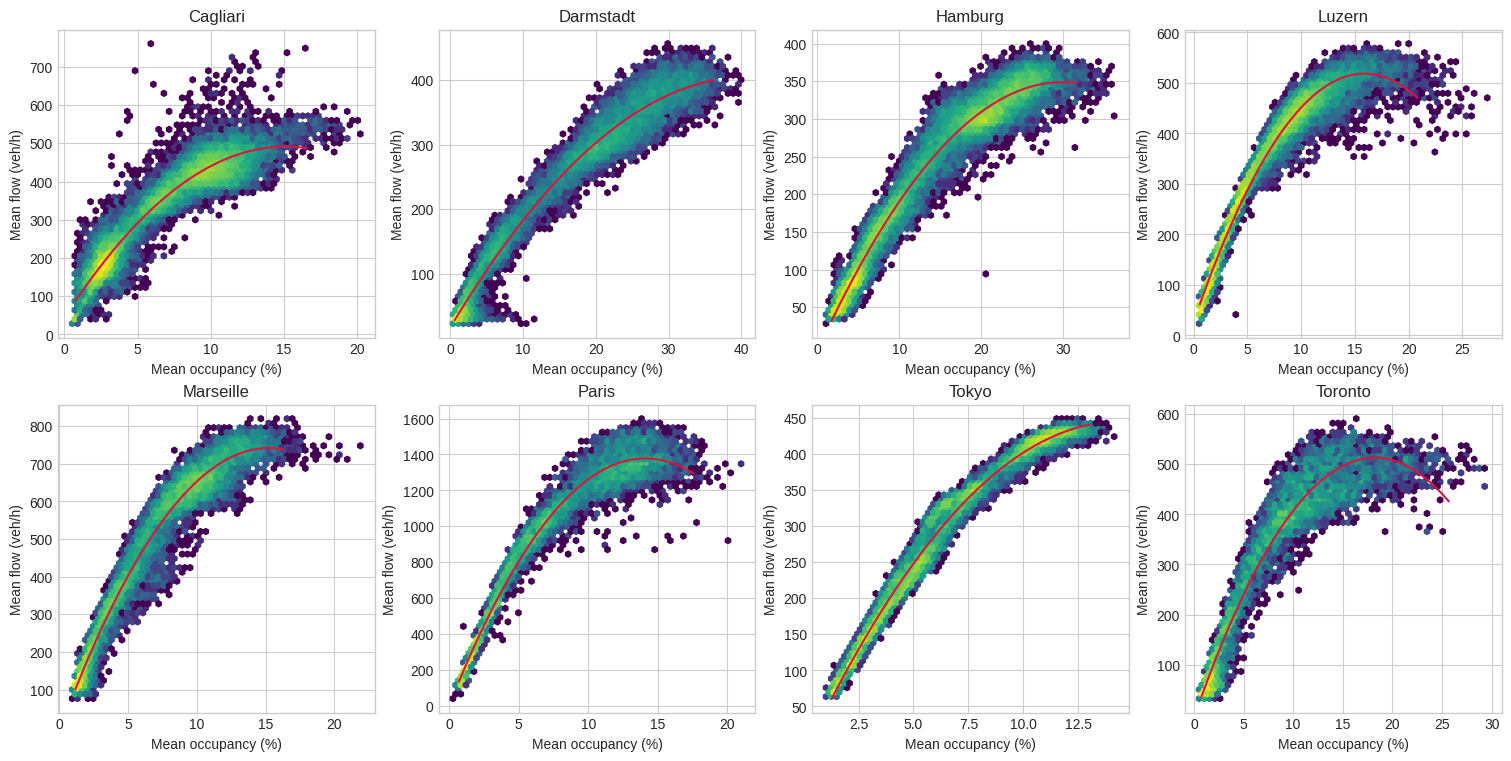

In [ ]:
plt.style.use('seaborn-v0_8-whitegrid')
fig,axs=plt.subplots(2,4,figsize=(15,7.5),constrained_layout=True)
for ax,city in zip(axs.flat,SELECTED):
    d=all_df[city]; samp=d.sample(min(25000,len(d)),random_state=7); s=summary[summary.city.eq(city)].iloc[0]
    hb=ax.hexbin(samp.occ_pct,samp.q,gridsize=55,mincnt=1,cmap='viridis',bins='log')
    xx=np.linspace(d.occ_pct.quantile(.005),d.occ_pct.quantile(.995),200); yy=s.beta0+s.beta1*xx+s.beta2*xx**2
    ax.plot(xx,yy,color='crimson',lw=1.5); ax.set_title(city.title()); ax.set_xlabel('Mean occupancy (%)'); ax.set_ylabel('Mean flow (veh/h)')
fig.savefig(FIG/'Figure_multicity_MFD.png',dpi=300); plt.show()

## 8. Contrastar con los resultados comprobados
Los CSV esperados están incorporados para comparar los resultados calculados con los del paquete v1.0. No se usan como entrada del ajuste.

In [ ]:
from io import StringIO
expected=pd.read_csv(StringIO('city,intervals,days,cadence_seconds,coverage_threshold,r2,beta0,beta1,beta2,critical_occupancy_pct,maximum_mean_flow,critical_ci_low,critical_ci_high,capacity_ci_low,capacity_ci_high,observed_critical_branch,k2_stability_mean_ari,k2_stability_min_ari\ncagliari,23989,50,180,48,0.9060399675150171,44.56398907132001,59.057500497936445,-1.9513895809145514,15.132165579734766,491.3979272013414,14.310600134788828,15.957653381097769,481.27634090744846,501.60457291186594,True,0.9998133218518818,0.9995999753968896\ndarmstadt,16708,35,180,87,0.9691025914288337,15.526290802956584,18.960340711957564,-0.23046826639589074,41.13438480807618,405.4872662719043,39.61543799901929,42.91879797085394,398.62859541663676,414.86189579916146,False,0.999872282464674,0.9997605296212638\nhamburg,48773,105,180,124,0.9675245103243056,-8.242418490723361,23.811593905737077,-0.39681114419307484,30.003685952619268,348.9753742987956,29.102156403123242,30.925492902787713,345.1970533514313,353.0033860178441,True,0.9998222228405347,0.9996000093977806\nluzern,161835,361,180,64,0.9761544179084229,27.125374460547974,61.94182919263594,-1.951882948397592,15.867198707660057,518.5470305182945,15.716457580347537,16.011480883419377,515.8525587511167,521.1360805026104,True,0.9998933320732158,0.9997999976372796\nmarseille,14346,30,180,76,0.9637027357068811,-10.258096495153787,98.65034927966667,-3.2349504536454456,15.247582720857162,741.8315840464311,14.780991151001299,15.76931841098579,729.3888911655409,755.1035626963311,True,0.9988046903931452,0.9972132992812057\nparis,8033,336,3600,92,0.9704840493881378,4.544993624638523,194.67359230711313,-6.898678794401631,14.109483722092795,1377.9169345139096,13.943890134208246,14.274500289992089,1369.7275721095334,1384.9126725418205,True,0.9931345652396876,0.984620606884164\ntokyo,17856,31,150,733,0.9866380767745183,-17.62404226279959,64.27018339522299,-2.234545585067107,14.381041010021026,444.5120293013375,13.835176024834803,15.033947144657441,437.6230541414647,454.1112169598489,False,0.9996963713440449,0.9988801568849763\ntoronto,5854,61,900,71,0.9277826497522548,-6.549690792474948,57.04267467235756,-1.565584977335923,18.217687157877627,513.0431101223251,17.591264243243497,18.811177661388896,505.57780341322996,521.1605671774103,True,0.9974633436764417,0.9938503325722706\n'))
actual=pd.read_csv(OUT/'multicity_mfd_summary.csv')
pd.testing.assert_frame_equal(actual,expected,check_dtype=False,rtol=1e-5,atol=1e-7)
print('multicity_mfd_summary.csv', 'coincide')
expected=pd.read_csv(StringIO('held_out_city,adjusted_rand_index,training_cities\ncagliari,0.9867030064032036,5\nhamburg,0.9944306850903342,5\nluzern,0.9333271975955614,5\nmarseille,0.9709332669895981,5\nparis,0.7375319047336525,5\ntoronto,0.9681061740979083,5\n'))
actual=pd.read_csv(OUT/'leave_one_city_out_transfer.csv')
pd.testing.assert_frame_equal(actual,expected,check_dtype=False,rtol=1e-5,atol=1e-7)
print('leave_one_city_out_transfer.csv', 'coincide')


multicity_mfd_summary.csv coincide
leave_one_city_out_transfer.csv coincide
